In [32]:
import sys
from pathlib import Path

# SAGE is not installed in this kernel: put the SAGE repo (the folder that holds sage/) on the path
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sage" / "__init__.py").exists()), None)
print(root)
if root is None:
    raise RuntimeError("SAGE repo not found above " + str(Path.cwd()) + ": run the notebook from inside it")
sys.path.insert(0, str(root))

import torch
from gwpy.timeseries import TimeSeries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sage.data.noise import sample_synthetic_noise
from sage.dsp.qtransform import QTransform
from sage.dsp import decimate
from sage.dsp.welch import TorchWelch
from sage.dsp.whiten import FIRWhitening


/home/melissa.lopez/sage


In [ ]:
def generate_data(start, end, fs=4096, highpass=15, keep=32):
    """V1 strain in [start, end]: decimated to fs, whitened with its own ASD, and the keep s centred on
    the middle of [start, end] kept. Returns the whitened series (float32, keep * fs samples), and the
    ASD's frequencies and values.

        white, f, asd = generate_data(t0 - 32, t0 + 32)     # 64 s fetched -> 32 s centred on t0
    """
    # Load data
    data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

    # Resample 16 kHz -> fs: half-band FIR anti-alias, x2 per pass (float64)
    x = decimate(torch.tensor(data.value), int(data.sample_rate.value) // fs)

    # Compute ASD: Welch, 4 s Hann segments, 2 s overlap, median
    f, psd = TorchWelch(delta_t=1 / fs, seg_len=4 * fs, seg_stride=2 * fs)(x, return_freqs=True)
    asd = psd.sqrt()

    # Whiten: filters in float64 (needed for real strain), returns float32; drops fduration / 2 = 1 s at each end
    whiten = FIRWhitening(fs, highpass=highpass, output_dtype=torch.float32)
    white = whiten(x, asd)

    # Crop: the keep s centred on the middle of [start, end] (white[0] is at data.t0 + 1 s)
    t0 = (start + end) / 2
    # i0 = round[(t0 - t_d - fduration / 2 - keep / 2) * fs], t_d = data.t0: derivation and picture in
    # eucaif/notes/centred_crop.pdf
    i0 = int(round((t0 - data.t0.value - whiten.pad / fs) * fs)) - keep * fs // 2
    if i0 < 0 or i0 + keep * fs > white.numel():
        raise ValueError("keep is too long for [start, end]: fetch more or keep less")
    return white[i0:i0 + keep * fs], f, asd

In [2]:
file = 'O3b_vigilant_train_set.csv'
df = pd.read_csv(file)
len(df['GPStime'])

11193

In [3]:
start, end = df['GPStime'].iloc[0] - 20, df['GPStime'].iloc[0] + 20
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

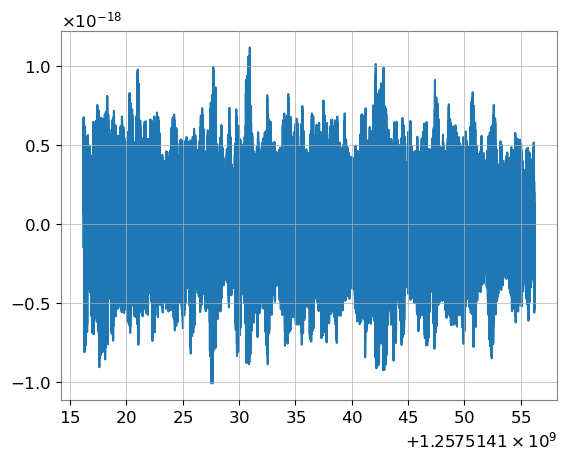

In [4]:
plt.plot(data)

In [7]:
fs, total, keep = 4096, 64, 32       # fetch 64 s around the glitch; after whitening keep the 32 s centred on it
t0 = df['GPStime'].iloc[0]
start, end = t0 - total / 2, t0 + total / 2
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

In [ ]:
%%time
# gwpy: resample 16 kHz -> 4 kHz, estimate the ASD, whiten, Q-transform; plot each step
data_4k = data.resample(fs)                                          # FIR anti-alias (scipy decimate) + downsample by 4
asd_gwpy = data_4k.asd(fftlength=4)                                 # Welch, 4 s Hann segments (defaults: 50% overlap, median)
white_gwpy = data_4k.whiten(asd=asd_gwpy, highpass=10)               # FIR inverse-spectrum truncation (default 2 s filter)
white_gwpy = white_gwpy.crop(t0 - keep / 2, t0 + keep / 2)           # the 32 s centred on the glitch (the whitening corrupts only 1 s at each end)
print(white_gwpy.duration)
q_gwpy = white_gwpy.q_transform(whiten=False, frange=(20, 1000), logf=True,
                                gps=t0, outseg=(t0 - 1, t0 + 1))     # defaults: Q 4-64, searched near t0; 1000 x 500 over +/- 1 s

fig, axs = plt.subplots(4, 1, figsize=(10, 12))
axs[0].plot(data_4k.times.value - t0, data_4k.value, lw=0.3)
axs[0].set(xlabel=f"time from {t0} [s]", ylabel="strain", title=f"gwpy: resampled to {fs} Hz")
axs[1].loglog(asd_gwpy.frequencies.value, asd_gwpy.value)
axs[1].set(xlim=(10, fs / 2), xlabel="frequency [Hz]", ylabel="ASD [1/sqrt(Hz)]", title="gwpy: ASD (median Welch)")
axs[2].plot(white_gwpy.times.value - t0, white_gwpy.value, lw=0.3)
axs[2].set(xlabel=f"time from {t0} [s]", ylabel="whitened strain", title=f"gwpy: whitened, std {white_gwpy.value.std():.2f}")
axs[3].pcolormesh(q_gwpy.times.value - t0, q_gwpy.frequencies.value, q_gwpy.value.T, shading="auto", vmin=0, vmax=25)
axs[3].set(yscale="log", xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]", title=f"gwpy: Q-transform, Q = {q_gwpy.q:.1f}")
axs[3].grid(False)
fig.tight_layout()

In [ ]:
#%%time
# SAGE: the same steps with SAGE's functions (float64 for real strain, see FIRWhitening's docstring);
# gwpy's results from the cell above are drawn in grey for comparison

data_torch = torch.tensor(data.value)
fs_old = int(data.sample_rate.value) # 16 kHz -> 4 kHz
x_sage = decimate(data_torch, fs_old // fs)   # half-band FIR anti-alias, x2 per pass

f_sage, psd_sage = TorchWelch(delta_t=1 / fs, seg_len=4 * fs, seg_stride=2 * fs)(x_sage, return_freqs=True)                         # frequencies (Hz) and PSD
asd_sage = psd_sage.sqrt()
whiten = FIRWhitening(fs, highpass=10.0, output_dtype=torch.float32)            # gwpy's whiten (default 2 s filter): filters in
                                                                                 # float64 (default, needed for real strain), returns float32
white_sage = whiten(x_sage, asd_sage)                                            # (T,) in -> (T - 2 s,) out: drops fduration / 2 = 1 s at each end
# keep the 32 s centred on the glitch: white_sage[0] is at data.t0 + 1 s (whiten.pad samples), so the
# glitch is at sample (t0 - that time) * fs; take keep / 2 s on each side of it
t_white0 = data.t0.value + whiten.pad / fs                                       # GPS time of white_sage[0]
i0 = int(round((t0 - t_white0) * fs)) - keep * fs // 2
if i0 < 0 or i0 + keep * fs > white_sage.numel():
    raise ValueError("the glitch is too close to the edge of the data: fetch more (total) or keep less")
white_sage = white_sage[i0:i0 + keep * fs]
tc = t0 - (t_white0 + i0 / fs)                                                   # glitch time, in s from the start of white_sage (~ keep / 2)
qt = QTransform(fs, white_sage.numel(), frange=(20, 1000), logf=True,
                outseg=(tc - 1, tc + 1))                                         # defaults as gwpy: Q 4-64, 1000 x 500 over +/- 1 s
q_sage, q = qt(white_sage, gps=tc, return_q=True)                                # Q searched near the glitch, as gwpy's gps=

t = data.t0.value - t0 + np.arange(x_sage.numel()) / fs                         # times of x_sage, from the glitch
fig, axs = plt.subplots(4, 1, figsize=(10, 12))
axs[0].plot(t, x_sage, lw=0.3)
axs[0].set(xlabel=f"time from {t0} [s]", ylabel="strain", title=f"SAGE: decimated to {fs} Hz")
axs[1].loglog(asd_gwpy.frequencies.value, asd_gwpy.value, color="0.75", lw=3, label="gwpy")
axs[1].loglog(f_sage, asd_sage, label="SAGE")
axs[1].set(xlim=(10, fs / 2), xlabel="frequency [Hz]", ylabel="ASD [1/sqrt(Hz)]", title="SAGE: ASD (TorchWelch, median)")
axs[1].legend()
axs[2].plot(white_gwpy.times.value - t0, white_gwpy.value, color="0.75", lw=0.6, label="gwpy")
axs[2].plot(np.arange(white_sage.numel()) / fs - tc, white_sage, lw=0.3, label="SAGE")
axs[2].set(xlabel=f"time from {t0} [s]", ylabel="whitened strain", title=f"SAGE: whitened, std {float(white_sage.std()):.2f}")
axs[2].legend()
axs[3].pcolormesh(qt.times - tc, qt.frequencies, q_sage.T, shading="auto", vmin=0, vmax=25)
axs[3].set(yscale="log", xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]", title=f"SAGE: Q-transform, Q = {float(q):.1f}")
axs[3].grid(False)
fig.tight_layout()

# how close to gwpy: only the resampling differs (gwpy/scipy's FIR blocks ~60 dB above 2048 Hz, SAGE's ~92 dB);
# given the same resampled data, the ASD, whitening and Q-transform agree with gwpy to ~1e-6
band = (f_sage >= 20) & (f_sage <= 1500)
ratio = (asd_sage / torch.tensor(asd_gwpy.value))[band]
print(f"ASD, SAGE / gwpy over 20-1500 Hz: median {float(ratio.median()):.4f}, range {float(ratio.min()):.3f}-{float(ratio.max()):.3f}")
print(f"whitened: std SAGE {float(white_sage.std()):.3f}, gwpy {white_gwpy.value.std():.3f}; "
      f"correlation {np.corrcoef(white_sage.numpy(), white_gwpy.value)[0, 1]:.4f}")
print(f"Q-transform: Q SAGE {float(q):.1f}, gwpy {q_gwpy.q:.1f}; largest difference "
      f"{float((q_sage - torch.tensor(q_gwpy.value)).abs().max() / q_gwpy.value.max()):.1e} of gwpy's peak "
      f"(from the resampling: gwpy's anti-alias filter lets through ~1e3 x more aliasing than SAGE's decimate)")

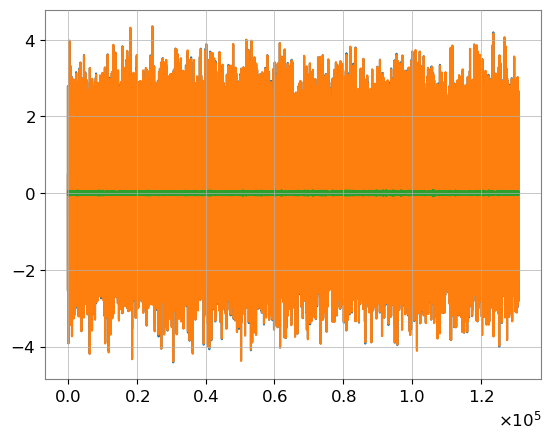

In [22]:

plt.plot(white_sage.numpy())
plt.plot(white_gwpy.value)
plt.plot(white_sage.numpy() - white_gwpy.value)

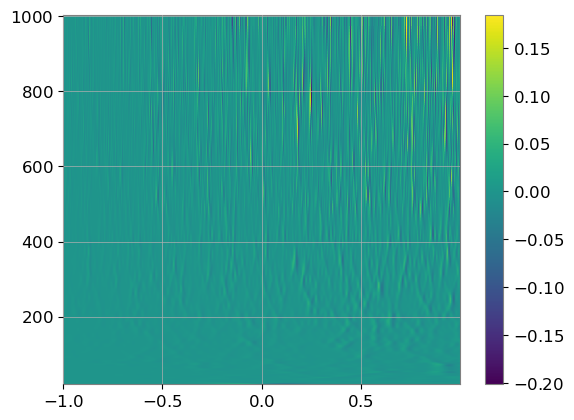

In [23]:
plt.pcolormesh(qt.times - tc, qt.frequencies,  q_gwpy.value.T - q_sage.numpy().T)
plt.colorbar()

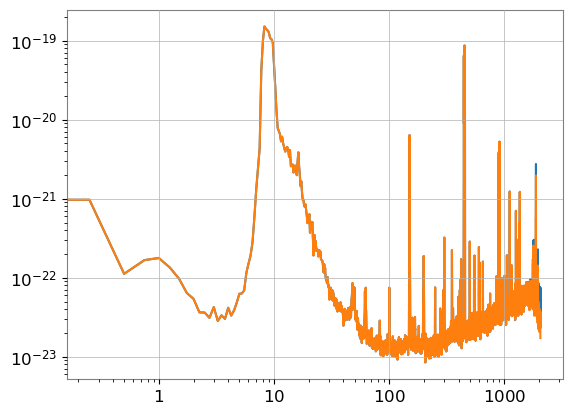

In [24]:
plt.loglog(f_sage.numpy(), asd_sage.numpy())
plt.loglog(asd_gwpy.frequencies, asd_gwpy.value)

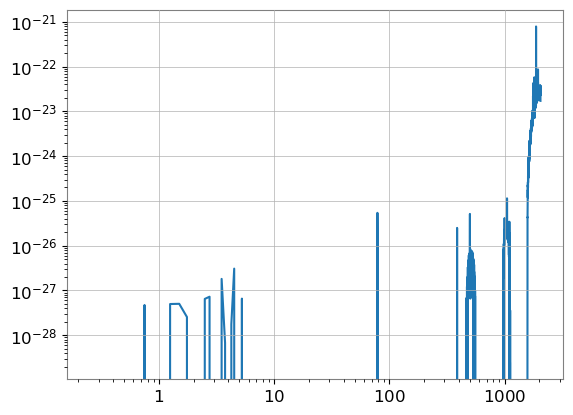

In [25]:
plt.loglog(f_sage.numpy(), asd_sage.numpy() - asd_gwpy.value)

In [86]:
# Store n glitches of the CSV in one HDF5 file: for each, the whitened keep s centred on its GPStime
# (float32) and its ASD, with the CSV row as metadata. Uses generate_data (cell 1) and df (the CSV).
import subprocess
import time
import h5py

def save_glitches(df, path, n, total=64, keep=32, fs=4096, highpass=10):

    rows, white, asds, seconds = [], [], [], []
    for i, row in df.head(n).iterrows():
        t0 = round(float(row['GPStime']), 3)                    # GPS time to 1 ms: the window is centred on it
        tic = time.perf_counter()
        try:
            w, f, asd = generate_data(t0 - total / 2, t0 + total / 2, fs=fs, highpass=highpass, keep=keep)
        except Exception as e:                                  # e.g. no data at that time: skip, keep going
            print(f"row {i} (GPS {t0}): skipped, {type(e).__name__}: {e}")
            continue
        seconds.append(time.perf_counter() - tic)               # this sample: fetch + decimate + ASD + whiten + crop
        rows.append(i)
        white.append(w.numpy())
        asds.append(asd.float().numpy())
    if not rows:
        raise RuntimeError("no glitch could be processed")
    meta = df.loc[rows]
    commit = subprocess.run(["git", "-C", str(root), "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
    with h5py.File(path, "w") as h:
        h["whitened"] = np.stack(white)                         # (n, keep * fs) float32, glitch at the centre
        g = h.create_group("metadata")   
        for col in meta.columns:
            if (col == 'GPStime') or (col == 'snr') or (col == 'confidence') or (col == 'label') or (col == 'new_label'):
                v = meta[col].to_numpy()
                if col == 'GPStime':
                    v = np.round(v.astype(np.float64), 3)           # stored to 1 ms, as used for the centring
                name = str(col).replace("/", "_")
                if v.dtype == object:
                    g.create_dataset(name, data=v.astype(str).tolist(), dtype=h5py.string_dtype())
                else:
                    g[name] = v
        h.attrs.update(sample_rate=fs, keep=keep, total=total, highpass=highpass, fduration=2.0, gps_decimals=3,
                       channel="V1:Hrec_hoft_16384Hz", frametype="HoftOnline",
                       whitening="SAGE decimate -> TorchWelch (4 s, median) -> FIRWhitening (float64)",
                       sage_commit=commit)
    print(f"saved {len(rows)} of {min(n, len(df))} glitches to {path}")
    s = np.array(seconds)                                       # time per generated sample (skipped ones not counted)
    var = s.var(ddof=1) if s.size > 1 else 0.0
    print(f"time per sample ({s.size} samples): mean {s.mean():.3f} s, variance {var:.3g} s^2 (std {var ** 0.5:.3f} s), "
          f"min {s.min():.3f} s, max {s.max():.3f} s")

save_glitches(df, "virgo_glitches.h5", n=100)

# reading it back:
# with h5py.File("virgo_glitches.h5") as h:
#     x = h["whitened"][:]                  # (n, 131072)
#     gps = h["metadata/GPStime"][:]        # (n,) numbers come back as numbers
#     labels = h["metadata/label"].asstr()[:]   # text columns: .asstr() gives str instead of bytes

saved 100 of 100 glitches to virgo_glitches.h5


In [83]:
f = h5py.File('virgo_glitches.h5')
print(f.keys())
print(f['metadata'].keys())

print(f['whitened'][:].shape)


f.close()

<KeysViewHDF5 ['metadata', 'whitened']>
<KeysViewHDF5 ['GPStime', 'confidence', 'label', 'new_label', 'snr']>
(10, 131072)
